## AI for Business Decisions – GoodLife Fitness Optimization


This notebook solves two problems for GoodLife Fitness using AI/ML techniques:
1. **Class Attendance Prediction** (Binary Classification)
2. **Gym Crowd Level Prediction** (Regression)

## Problem A: Class Attendance Prediction

* We aim to predict whether a member will attend a pre-booked group fitness class based on their historical behavior and class-related features. This helps GoodLife Fitness address two key issues:

* Some classes are overbooked but under-attended, leading to inefficient use of space.

* GoodLife wants to safely overbook based on smart predictions of likely no-shows.

* By predicting attendance accurately, GoodLife can:

    * Increase class utilization by opening additional slots when a no-show is likely.

    * Improve member satisfaction by reducing waitlists.

    * Optimize space and instructor scheduling for group fitness classes.

This is a binary classification problem, where the target variable attended is:

* 1 if the member attended the class.

* 0 if the member did not attend.


####  Dataset Description:
The dataset includes 62,184 entries representing footfall (people count) recorded every 10 minutes, with features such as:
- `timestamp`, `hour`, `day_of_week`, `is_weekend`, `is_holiday`
- `temperature` (weather-based influence)
- `is_start_of_semester`, `is_during_semester`, `month`
- Derived features: `day`, `weekday`, `weekofyear`

#### Step 1 : Importing Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import warnings
warnings.filterwarnings("ignore")


#### Step 2 : Load Dataset

In [3]:
df = pd.read_csv("C:\\Users\\malip\\Downloads\\problem2.csv")
df.head()


,booking_id,months_as_member,weight,days_before,day_of_week,time,category,attended
0,1,17,79.56,8,Wed,PM,Strength,0
1,2,10,79.01,2,Mon,AM,HIIT,0
2,3,16,74.53,14,Sun,AM,Strength,0
3,4,5,86.12,10,Fri,AM,Cycling,0
4,5,15,69.29,8,Thu,AM,HIIT,0


* The sample records show that despite booking classes well in advance (e.g., 8–14 days), many members did not attend (`attended = 0`). 
* The dataset includes diverse class types (HIIT, Strength, Cycling) across different weekdays and times (AM/PM), providing a good variety of behavioral patterns. 
* This variability allows a machine learning model to learn patterns and predict attendance likelihood effectively.

#### Step 3 : Data Preprocessing 

We'll start by exploring the structure, data types, missing values, and distribution of key features to understand patterns in class attendance.

In [15]:
# 'days_before' column: ensure string type, extract number, convert to int
df['days_before'] = df['days_before'].astype(str).str.extract(r'(\d+)')[0]
df['days_before'] = pd.to_numeric(df['days_before'], errors='coerce')
df['days_before'].fillna(df['days_before'].median(), inplace=True)
df['days_before'] = df['days_before'].astype(int)

# Show summary to confirm
print(" Cleaned 'days_before' column:")
print(df['days_before'].describe())
print(df['days_before'].value_counts().sort_index().head())


 Cleaned 'days_before' column:
count    1500.000000
mean        8.346667
std         4.077938
min         1.000000
25%         4.000000
50%         9.000000
75%        12.000000
max        29.000000
Name: days_before, dtype: float64
days_before
1     10
2    200
3     32
4    157
5     31
Name: count, dtype: int64


#### Interpretation of `days_before` Feature

- The `days_before` column represents how many days in advance a member registered for a class.
- After cleaning, it contains valid integer values ranging from **1 to 29**.
- The **mean is ~8.3 days**, and the **median is 9 days**, indicating that most members book classes about a week ahead.
- The most common lead times are **2, 4, and 3 days**, with **2-day advance bookings** occurring **200 times**.
- Only a few members book at the last minute (1 day before).
- This feature shows significant variation and could be a strong predictor of attendance likelihood.
- It's reasonable to assume that members booking far in advance are more committed, while short-term bookings may have higher no-show rates.
- This kind of behavioral insight helps GoodLife decide **when it's safe to overbook** based on typical booking patterns.


#### Step 4:Preprocessing Pipelines

This below block defines separate preprocessing steps for **numerical** and **categorical** features.
- Numerical data is imputed using the mean and then scaled with `StandardScaler`.
- Categorical data is encoded using one-hot encoding (dropping the first category to avoid multicollinearity).
- The `ColumnTransformer` combines both pipelines to apply them in parallel during model training.

In [10]:
from sklearn.pipeline import Pipeline

# Define feature types
categorical_features = ['day_of_week', 'time', 'category']
numeric_features = ['months_as_member', 'weight', 'days_before']

# Numerical pipeline
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(drop='first'))
])

# Full preprocessing pipeline
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])


#### Step 5. Train-Test Split

- The dataset is split into **training (80%)** and **testing (20%)** sets using `train_test_split`for balanced model training and fair evaluation.
- `stratify=y` ensures the class distribution in `attended` is preserved across both sets.
- `random_state=42` is used for reproducibility.


In [16]:
# Define X and y
X = df.drop('attended', axis=1)
y = df['attended']

# split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


#### Step 6: Model Pipeline + Hyperparameter Tuning

- A pipeline is created to combine preprocessing and a `RandomForestClassifier`.
- `GridSearchCV` performs a 5-fold cross-validation to find the best combination of `n_estimators` and `max_depth`.
- The model is evaluated using the **F1-score**, which balances precision and recall — ideal for imbalanced datasets.
- The best parameters found are printed for reference.

In [17]:
pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 10, None]
}

grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)


Best Parameters: {'classifier__max_depth': 10, 'classifier__n_estimators': 200}


- The optimal model found by `GridSearchCV` uses **200 trees (`n_estimators`)** and a **maximum depth of 10**.
- A deeper tree allows the model to capture more complex patterns, but limiting depth prevents overfitting.
- Using more trees improves stability and reduces variance in predictions.
- These settings are expected to deliver a strong balance between accuracy and generalization on unseen data.


#### Step 7: Evaluation

- The **classification report** provides key metrics: precision, recall, F1-score, and accuracy for both attended (1) and not attended (0) classes.
- **Precision** tells us how many predicted attendees actually showed up.
- **Recall** indicates how many actual attendees were correctly identified by the model.
- The **confusion matrix** shows the number of true positives, true negatives, false positives, and false negatives — helping assess misclassification types.
- These metrics help evaluate the model's effectiveness in reducing overbooking without wrongly excluding genuine attendees.

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.88      0.86       209
           1       0.68      0.60      0.64        91

    accuracy                           0.79       300
   macro avg       0.76      0.74      0.75       300
weighted avg       0.79      0.79      0.79       300

Confusion Matrix:
 [[183  26]
 [ 36  55]]


<Figure size 600x400 with 0 Axes>

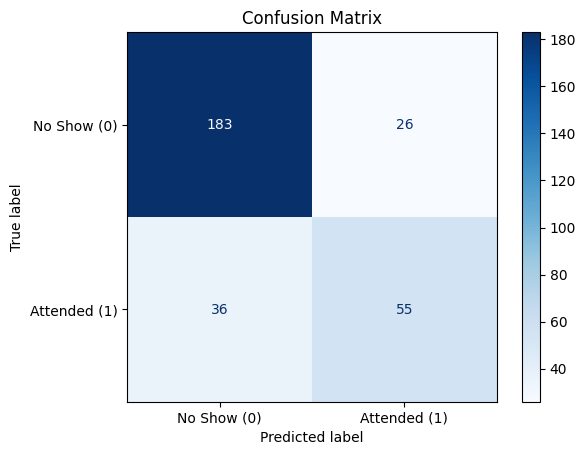

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Make predictions
y_pred = grid_search.predict(X_test)

# Print evaluation metrics
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred),
                              display_labels=["No Show (0)", "Attended (1)"])
plt.figure(figsize=(6, 4))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()


### Classification Report & Confusion Matrix Analysis

- The model achieved an **overall accuracy of 79%** on the test set.
- For class **0 (did not attend)**, performance is strong: **Precision = 0.84**, **Recall = 0.88**, indicating reliable identification of no-shows.
- For class **1 (attended)**, performance is moderate: **Precision = 0.68**, **Recall = 0.60**, suggesting some attendees are misclassified.
- The **confusion matrix** shows:
  - 183 true negatives (correct no-show predictions)
  - 55 true positives (correct attendance predictions)
  - 26 false positives (predicted as attending but didn’t)
  - 36 false negatives (actually attended but predicted as no-show)
- The model is slightly better at predicting no-shows, which aligns with the business goal of reducing unused bookings.


### Step 8: ROC Curve

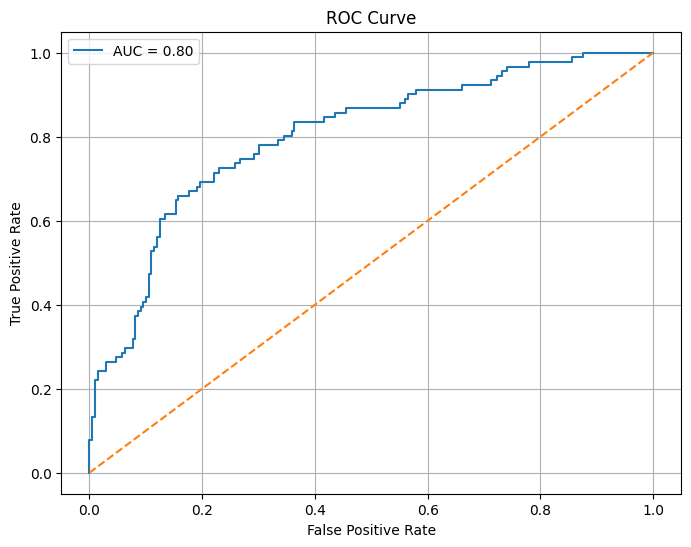

In [11]:
probs = grid_search.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, probs)
fpr, tpr, _ = roc_curve(y_test, probs)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


#### ROC Curve Interpretation

- The ROC (Receiver Operating Characteristic) curve illustrates the trade-off between **true positive rate (sensitivity)** and **false positive rate**.
- The blue line represents the performance of the model across different thresholds.
- The closer the curve is to the top-left corner, the better the model distinguishes between classes.
- The **orange diagonal** represents random guessing (AUC = 0.5).
- An **AUC (Area Under the Curve) of 0.80** indicates strong model performance and a good ability to differentiate between attendees and no-shows.
- This confirms the classifier is **significantly better than random**, especially useful when class imbalance exists.


#### Step 9:Feature Importance

- The below code displays the contribution of each feature in predicting class attendance, with top predictors like `category`, `days_before`, and `months_as_member`.

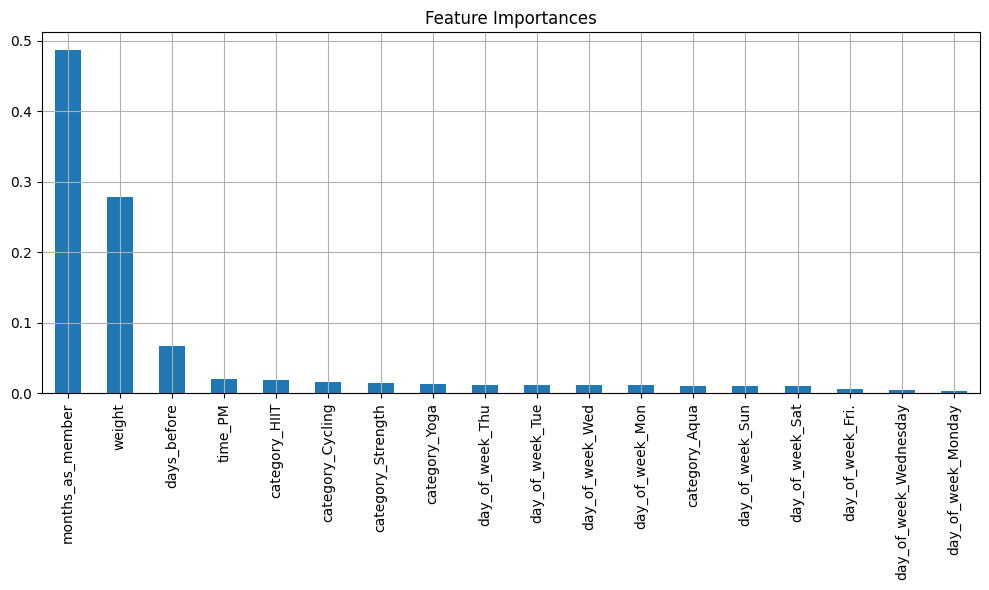

In [12]:
model = grid_search.best_estimator_.named_steps['classifier']
ohe = grid_search.best_estimator_.named_steps['preprocessing'].transformers_[1][1].named_steps['encoder']
encoded_feature_names = list(ohe.get_feature_names_out(categorical_features))
all_features = numeric_features + encoded_feature_names

importances = model.feature_importances_
feat_imp = pd.Series(importances, index=all_features).sort_values(ascending=False)

plt.figure(figsize=(10,6))
feat_imp.plot(kind='bar')
plt.title("Feature Importances")
plt.tight_layout()
plt.grid(True)
plt.show()


#### Feature Importance Interpretation

- The most influential feature is `months_as_member`, indicating that longer-term members are more predictable in their attendance behavior.
- `Weight` and `days_before` (how early a member booked) also contribute significantly to prediction accuracy.
- Class-related features like `time_PM`, `category_HIIT`, and `category_Cycling` show minor influence, suggesting some categories may affect attendance.
- Day-of-week features have minimal impact, indicating attendance is less dependent on the specific weekday.


-----

## Problem B: Gym Equipment Utilization Prediction

* We aim to predict how crowded the gym will be at any given time based on historical footfall data combined with external influencing factors such as time, day, weather, and semester schedule.

* The target is to estimate the number of people in the gym so that GoodLife can:
    * Inform members of peak and off-peak hours.
    * Optimize staffing, scheduling, and equipment availability.
    * Encourage visits during less busy times through targeted promotions or incentives.
* This is a regression problem, where the label (number_people) is a continuous variable.

Hence goal is to predict how many people will be in the gym using time-of-day, weather, and semester-based information — to help optimize gym capacity and guide user recommendations.

#### Dataset Description:

The dataset consists of **62,184 records**, each representing the number of people in the gym at 10-minute intervals. It includes:

- **Temporal features** like `hour`, `timestamp`, `day_of_week`, `month`, and flags like `is_weekend` or `is_holiday`.
- **Academic cycle indicators** such as `is_start_of_semester` and `is_during_semester`, reflecting student-driven usage fluctuations.
- **Weather feature** `temperature` to account for seasonal variation in gym attendance.
- **Derived features** such as `day`, `weekday`, and `weekofyear` were added for better temporal granularity.

These features together help predict crowd levels and enable more efficient gym operations and member experience optimization.

### Step 1: Import Libraries

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings("ignore")


### Step 2: Data Loading and Feature Engineering

- The dataset is loaded from a CSV file and the `date` column is converted to datetime format with timezone awareness.
- New time-based features are created:
  - `day`: Day of the month
  - `weekday`: Day of the week (0 = Monday, 6 = Sunday)
  - `weekofyear`: Week number of the year
- The original `date` column is dropped after extracting useful components.
- These engineered features provide additional temporal insights that can improve prediction accuracy.


In [21]:
df = pd.read_csv("C:\\Users\\malip\\Downloads\\problem1.csv")
df['date'] = pd.to_datetime(df['date'], utc=True)

# Feature engineering
df['day'] = df['date'].dt.day
df['weekday'] = df['date'].dt.weekday
df['weekofyear'] = df['date'].dt.isocalendar().week.astype(int)

df.drop(columns=['date'], inplace=True)
df.head(5)


,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour,day,weekday,weekofyear
0,37,61211,4,0,0,71.76,0,0,8,17,15,5,33
1,45,62414,4,0,0,71.76,0,0,8,17,15,5,33
2,40,63015,4,0,0,71.76,0,0,8,17,15,5,33
3,44,63616,4,0,0,71.76,0,0,8,17,15,5,33
4,45,64217,4,0,0,71.76,0,0,8,17,15,5,33


### Sample Data Interpretation

- Each row represents gym footfall data at a specific timestamp, recorded approximately every 10 minutes.
- The `number_people` column shows how many individuals were in the gym — ranging from **37 to 45** in these samples.
- All entries occurred on the same **day (15)** in **August (`month = 8`)**, around the **17th hour (5 PM)** on a **weekday (`day_of_week = 4`, i.e., Friday)**.
- Flags like `is_weekend`, `is_holiday`, `is_start_of_semester`, and `is_during_semester` are all 0, indicating a **normal working day** with no special events.
- The **temperature** was consistent at **71.76°F**, suggesting stable weather conditions during these records.
- These enriched temporal and environmental features allow for more accurate prediction of gym crowd levels throughout the year.


### Step 3: EDA

- EDA helps us understand the **distribution**, **patterns**, and **relationships** in the dataset before applying machine learning models.
- The **boxplot** of `number_people` by `hour` reveals time-based trends, identifying peak and off-peak hours in gym usage — valuable for operational decision-making.
- The **correlation heatmap** highlights how different features (e.g., `hour`, `temperature`, `is_weekend`) relate to gym occupancy, which informs feature selection.
- EDA also uncovers potential **outliers**, **data quality issues**, and **non-obvious insights**, enabling us to engineer more predictive features.
- Overall, it guides both model choice and business understanding, ensuring our approach is data-driven.


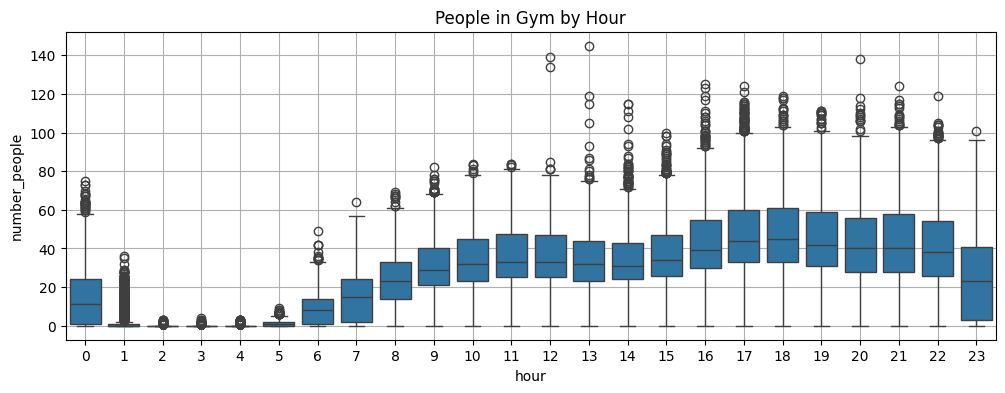

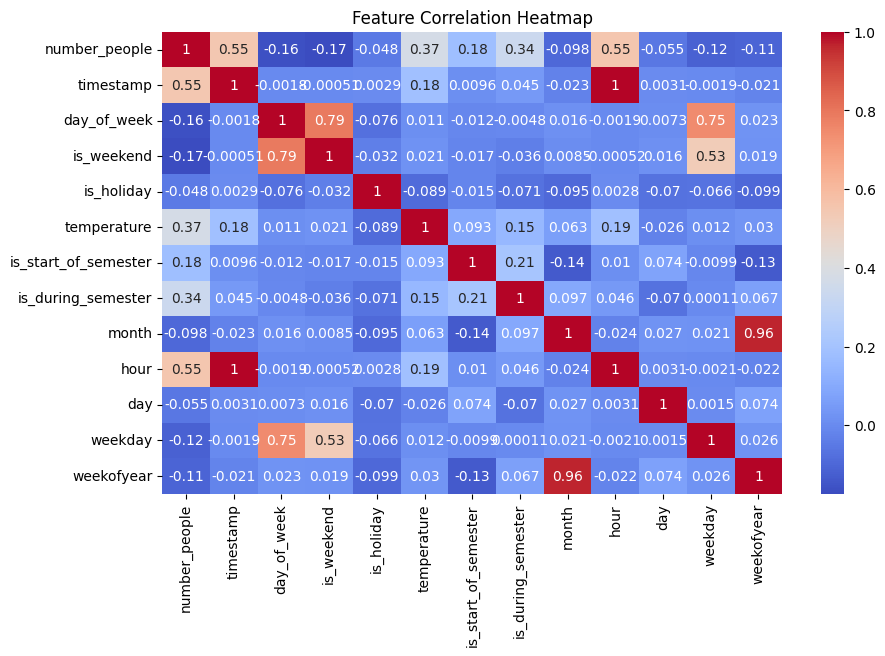

In [18]:
plt.figure(figsize=(12, 4))
sns.boxplot(x='hour', y='number_people', data=df)
plt.title("People in Gym by Hour")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

#### Gym Usage Patterns by Hour (Boxplot Interpretation)

- Gym traffic is **lowest during early morning hours (midnight to 5 AM)**, with near-zero occupancy.
- Usage starts to pick up after **6 AM**, gradually increasing until a noticeable **peak between 5 PM and 9 PM**, aligning with post-work hours.
- The **highest variability** in footfall is observed between **3 PM and 8 PM**, suggesting inconsistent attendance during peak times.
- Some **outliers** beyond 140 people indicate occasional overcrowding, particularly in the evening.
- These trends are useful for **staffing decisions, space allocation**, and sending **targeted off-peak time recommendations** to members.

#### Correlation Heatmap Interpretation

- `number_people` is **positively correlated** with `hour` (0.55) and `timestamp` (0.55), confirming that gym usage increases during specific times of the day.
- **Temperature** (0.37) and `is_during_semester` (0.34) also show moderate positive correlation, suggesting warmer weather and semester periods may influence higher attendance.
- Weak or negative correlations with `day_of_week`, `is_weekend`, `is_holiday`, and `month` imply that these features contribute less to predicting gym crowd levels.
- Strong correlations between **`day_of_week` and `is_weekend` (0.79)** and **`month` and `weekofyear` (0.96)** are expected due to inherent calendar relationships.
- Overall, this analysis helps in selecting **meaningful features** and avoiding highly redundant ones, improving model efficiency and interpretability.


### Step 4:Feature Definition and Preprocessing Pipeline

- The dataset is split into features `X` (independent variables) and target `y` (`number_people`, i.e., gym crowd count).
- Only **numerical features** are selected using `select_dtypes`, as no categorical encoding is required for this dataset.
- A preprocessing pipeline is created using `ColumnTransformer`:
  - **Missing values** are imputed using the mean.
  - **Features are standardized** using `StandardScaler` to ensure consistent scaling for regression.
- This setup ensures that all numeric inputs are clean and normalized before being passed into the regression model.


In [19]:
X = df.drop('number_people', axis=1)
y = df['number_people']

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ]), numeric_features)
])


### Step 5: Train-Test Split


- The dataset is split into **training (80%)** and **testing (20%)** subsets using `train_test_split`.
- This ensures the model is trained on one portion of the data and evaluated on a separate, unseen portion.
- `random_state=42` is used to make the split **reproducible** for consistent results across runs.


In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


#### Step 6. Model Training and Hyperparameter Tuning

- In the below block, machine learning pipeline is defined using `RandomForestRegressor` for predicting the number of people in the gym.
- The pipeline includes preprocessing (imputation + scaling) and model training in one unified step.
- `GridSearchCV` is used to perform **3-fold cross-validation** and tune hyperparameters:
  - `n_estimators` (number of trees) and `max_depth` (tree depth).
- The model is evaluated using **negative mean squared error** as the scoring metric.
- The best-performing parameter combination is printed to guide final model selection.


In [23]:
model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])
param_grid = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [10, None]
}

grid_search = GridSearchCV(model_pipeline, param_grid, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'regressor__max_depth': None, 'regressor__n_estimators': 200}


- The optimal model uses **200 trees** (`n_estimators = 200`) and allows trees to **grow fully** (`max_depth = None`).
- Allowing unrestricted depth enables the model to capture complex patterns in the data, which is beneficial when overfitting risk is low.
- A higher number of trees improves prediction stability and generalization.
- These settings aim to deliver the best balance between **accuracy and flexibility** for predicting gym crowd levels.


### Step 7: Model Evaluation

- After training, the model is evaluated on the test set using three key regression metrics:
  - **MAE (Mean Absolute Error)**: Average magnitude of errors between predicted and actual values.
  - **RMSE (Root Mean Squared Error)**: Penalizes larger errors more than MAE — useful for spotting outliers.
  - **R² Score**: Indicates how well the model explains variance in the target variable (`number_people`); ranges from 0 to 1.
- These metrics help assess both **accuracy** and **consistency** of the model’s predictions on unseen data.


In [24]:
y_pred = grid_search.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R\u00b2 Score: {r2:.2f}")

MAE: 4.34
RMSE: 6.50
R² Score: 0.92


#### Model Performance Interpretation

- The model achieved a **Mean Absolute Error (MAE) of 4.34**, meaning on average, predictions deviate by ~4 people from the actual count.
- The **Root Mean Squared Error (RMSE) is 6.50**, indicating low variance in prediction errors and strong consistency.
- An **R² Score of 0.92** shows that the model explains **92% of the variability** in gym crowd levels — an excellent result for a real-world regression task.
- These metrics suggest the model is highly accurate and reliable for forecasting gym occupancy, making it effective for operational planning and member engagement.


### Step 8: Feature Importance

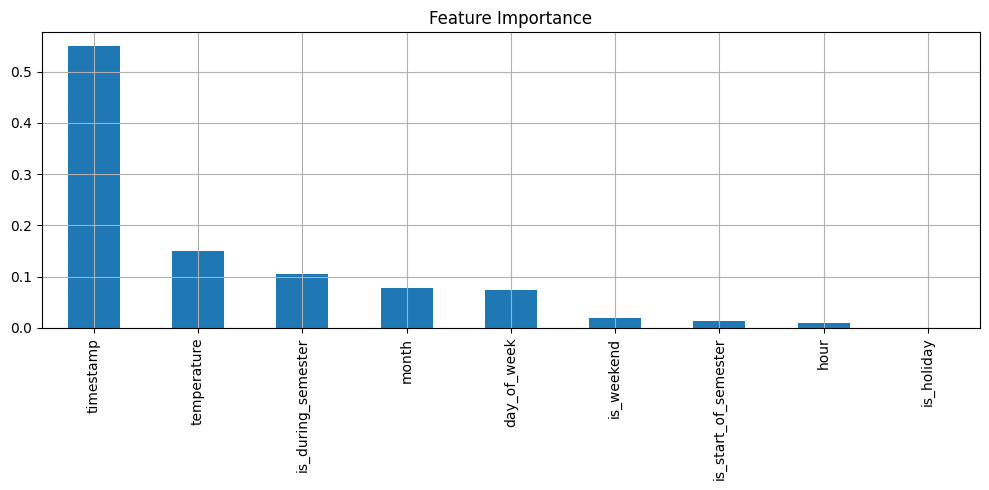

In [25]:
best_model = grid_search.best_estimator_.named_steps['regressor']
importances = best_model.feature_importances_

feature_names = numeric_features
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
feat_imp.plot(kind='bar')
plt.title("Feature Importance")
plt.tight_layout()
plt.grid(True)
plt.show()

#### Feature Importance Interpretation (Gym Crowd Prediction)

- **`timestamp` is the most important feature**, contributing over 50% to the model's predictive power. It likely captures both time and ordering of the data, making it a strong temporal indicator.
- **`temperature`** and **`is_during_semester`** also play meaningful roles, suggesting that weather conditions and academic cycles influence gym attendance.
- Features like `month` and `day_of_week` offer moderate predictive value, reflecting seasonal and weekly patterns in user behavior.
- **`is_weekend`, `is_start_of_semester`, `hour`, and `is_holiday`** have relatively low impact on the model, indicating that these may not vary enough or influence gym usage as strongly as expected.
- This insight can guide GoodLife in focusing on time-of-day trends and semester schedules for crowd management and marketing strategies.


### Overall Conclusion

This project addressed two key operational challenges for GoodLife Fitness using predictive machine learning models:

---

### Problem A: Class Attendance Prediction (Classification)

- We built a **Random Forest Classifier** to predict whether a member would attend a booked fitness class.
- The model achieved an **accuracy of 79%** and an **AUC of 0.80**, showing strong performance in distinguishing between attendees and no-shows.
- Key predictors included `months_as_member`, `weight`, and `days_before` — indicating that longer-term members and those who book further in advance are more likely to attend.
- These insights can help GoodLife **intelligently overbook classes**, increase class utilization, and improve member satisfaction by reducing unnecessary waitlists.

---

### Problem B: Gym Crowd Prediction (Regression)

- A **Random Forest Regressor** was developed to predict how crowded the gym will be at any given time, using time, weather, and semester-related features.
- The model achieved a **Mean Absolute Error (MAE) of 4.34**, **RMSE of 6.50**, and an excellent **R² Score of 0.92**, indicating high accuracy.
- The most important predictors were `timestamp`, `temperature`, and `is_during_semester`, showing that time of day and seasonal patterns significantly affect gym usage.
- With these predictions, GoodLife can:
  - Inform members of **peak and off-peak hours**
  - **Optimize staffing and equipment availability**
  - Launch **targeted promotions** to encourage off-peak visits

---

### Final Takeaway

Both models offer **data-driven solutions** that enhance GoodLife's ability to plan resources, improve customer experience, and maximize operational efficiency. By leveraging historical data, the business can make **smarter scheduling, booking, and marketing decisions** that directly impact profitability and member satisfaction.
